In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, log_loss

import pickle
import joblib

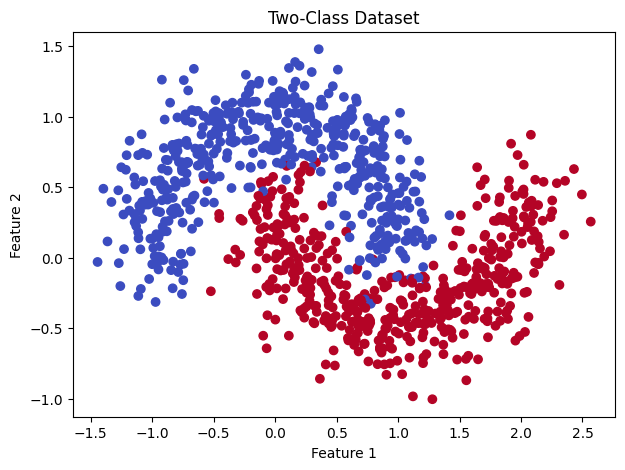

In [2]:
X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm")
plt.title("Two-Class Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 800
Testing samples: 200


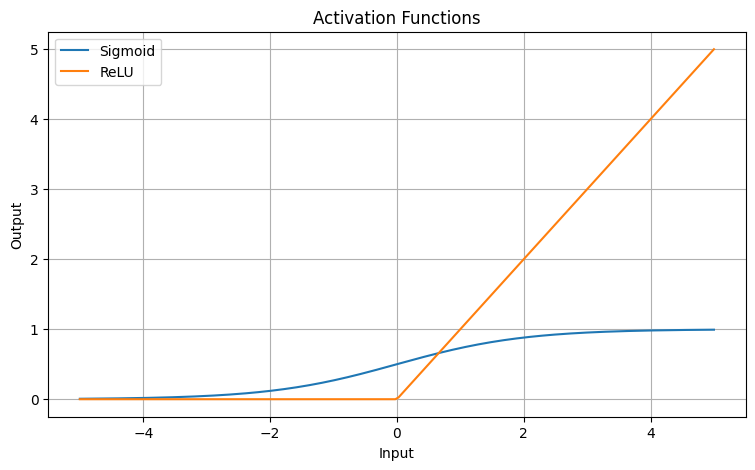

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def sigmoid_derivative(a):
    return a * (1 - a)

def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(float)

x = np.linspace(-5, 5, 200)

plt.figure(figsize=(9, 5))
plt.plot(x, sigmoid(x), label="Sigmoid")
plt.plot(x, relu(x), label="ReLU")
plt.title("Activation Functions")
plt.xlabel("Input")
plt.ylabel("Output")
plt.legend()
plt.grid(True)
plt.show()

In [5]:
np.random.seed(42)

input_size = 2
hidden_size = 8
output_size = 1

W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * np.sqrt(1 / hidden_size)
b2 = np.zeros((1, output_size))

print("W1:", W1.shape)
print("b1:", b1.shape)
print("W2:", W2.shape)
print("b2:", b2.shape)

W1: (2, 8)
b1: (1, 8)
W2: (8, 1)
b2: (1, 1)


In [6]:
def forward_propagation(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = relu(Z1)

    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)

    cache = (X, Z1, A1, Z2, A2)

    return A2, cache

In [7]:
def binary_cross_entropy(y_true, y_pred):
    eps = 1e-8
    y_pred = np.clip(y_pred, eps, 1 - eps)

    return -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

In [8]:
def backpropagation(y, cache, W2):
    X, Z1, A1, Z2, A2 = cache
    m = X.shape[0]

    dZ2 = (A2 - y) / m
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * relu_derivative(Z1)

    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2

Epoch 0, Loss: 1.3321
Epoch 200, Loss: 0.3328
Epoch 400, Loss: 0.3161
Epoch 600, Loss: 0.3118
Epoch 800, Loss: 0.3090
Epoch 1000, Loss: 0.3068
Epoch 1200, Loss: 0.3045
Epoch 1400, Loss: 0.3018
Epoch 1600, Loss: 0.2996
Epoch 1800, Loss: 0.2973


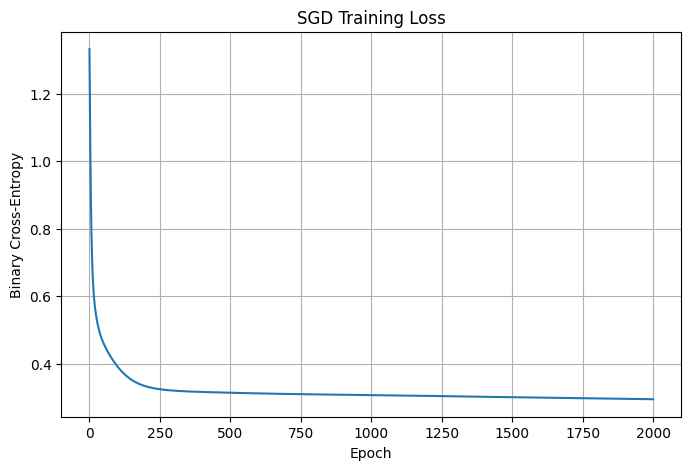

In [9]:
learning_rate = 0.05
epochs = 2000
loss_history = []

for epoch in range(epochs):
    predictions, cache = forward_propagation(
        X_train, W1, b1, W2, b2
    )

    loss = binary_cross_entropy(y_train, predictions)
    loss_history.append(loss)

    dW1, db1, dW2, db2 = backpropagation(
        y_train, cache, W2
    )

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    if epoch % 200 == 0:
        print(f"Epoch {epoch}, Loss: {loss:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.title("SGD Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")
plt.grid(True)
plt.show()

In [10]:
test_probabilities, _ = forward_propagation(
    X_test, W1, b1, W2, b2
)

test_predictions = (test_probabilities >= 0.5).astype(int)

accuracy = accuracy_score(
    y_test.ravel(),
    test_predictions.ravel()
)

print("Neural Network Test Accuracy:", round(accuracy, 4))
print(
    "Test Loss:",
    round(binary_cross_entropy(y_test, test_probabilities), 4)
)

Neural Network Test Accuracy: 0.9
Test Loss: 0.2194


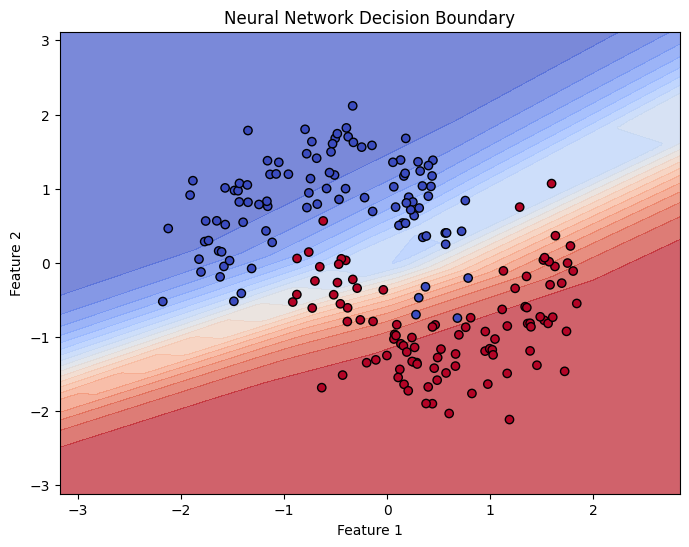

In [11]:
x_min, x_max = X_test[:, 0].min() - 1, X_test[:, 0].max() + 1
y_min, y_max = X_test[:, 1].min() - 1, X_test[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]

grid_probabilities, _ = forward_propagation(
    grid, W1, b1, W2, b2
)

plt.figure(figsize=(8, 6))
plt.contourf(
    xx, yy,
    grid_probabilities.reshape(xx.shape),
    levels=20,
    cmap="coolwarm",
    alpha=0.7
)

plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test.ravel(),
    cmap="coolwarm",
    edgecolors="black"
)

plt.title("Neural Network Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [12]:
results = []

for optimizer in ["sgd", "adam"]:
    model = MLPClassifier(
        hidden_layer_sizes=(8,),
        activation="relu",
        solver=optimizer,
        learning_rate_init=0.01,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train, y_train.ravel())

    predictions = model.predict(X_test)

    results.append({
        "Optimizer": optimizer.upper(),
        "Accuracy": accuracy_score(y_test.ravel(), predictions),
        "Final Training Loss": model.loss_
    })

optimizer_results = pd.DataFrame(results)
optimizer_results

,Optimizer,Accuracy,Final Training Loss
0,SGD,0.98,0.103349
1,ADAM,0.99,0.073025


In [13]:
deployment_model = MLPClassifier(
    hidden_layer_sizes=(8,),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=42
)

deployment_model.fit(X_train, y_train.ravel())

print(
    "Deployment model accuracy:",
    round(deployment_model.score(X_test, y_test.ravel()), 4)
)

Deployment model accuracy: 0.985


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


In [14]:
with open("neural_network_model.pkl", "wb") as file:
    pickle.dump(deployment_model, file)

with open("scaler.pkl", "wb") as file:
    pickle.dump(scaler, file)

print("Model and scaler saved using pickle.")

Model and scaler saved using pickle.


In [15]:
with open("neural_network_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

with open("scaler.pkl", "rb") as file:
    loaded_scaler = pickle.load(file)

sample = np.array([[0.5, 0.5]])
sample_scaled = loaded_scaler.transform(sample)

prediction = loaded_model.predict(sample_scaled)
probability = loaded_model.predict_proba(sample_scaled)

print("Predicted class:", prediction[0])
print("Class probabilities:", probability[0])

Predicted class: 0
Class probabilities: [0.84748997 0.15251003]


In [16]:
joblib.dump(deployment_model, "neural_network_model.joblib")
joblib.dump(scaler, "scaler.joblib")

loaded_model_joblib = joblib.load("neural_network_model.joblib")
loaded_scaler_joblib = joblib.load("scaler.joblib")

sample_scaled = loaded_scaler_joblib.transform(sample)

print(
    "Prediction after joblib loading:",
    loaded_model_joblib.predict(sample_scaled)[0]
)

Prediction after joblib loading: 0


In [17]:
np.savez(
    "numpy_neural_network_weights.npz",
    W1=W1,
    b1=b1,
    W2=W2,
    b2=b2
)

saved_parameters = np.load("numpy_neural_network_weights.npz")

W1_loaded = saved_parameters["W1"]
b1_loaded = saved_parameters["b1"]
W2_loaded = saved_parameters["W2"]
b2_loaded = saved_parameters["b2"]

print("NumPy network parameters saved and loaded.")

NumPy network parameters saved and loaded.
